# Evaluation harness and baselinesBefore any model: define what "beating RTE" means, and build the guard rails that stop usmeasuring it dishonestly.**What this notebook settles**1. The information constraint - what is knowable when the auction closes2. Proof that no feature reads past that moment3. The train / validation / test split4. The baselines a model must beat, and the bar they set

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from time_series_m2.baselines import naive
from time_series_m2.utils import metrics
from time_series_m2.utils.calendar_fr import add_calendar_features
from time_series_m2.utils.data import decision_time, information_cutoff, load_national
from time_series_m2.utils.features import (add_load_features, add_temperature_features,
                                           check_leakage)
from time_series_m2.utils.splits import describe, split_frame

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)

df = load_national()
print(f'{len(df)} hours, {df.index.min()} -> {df.index.max()}')

65710 hours, 2019-01-01 01:00:00+01:00 -> 2026-06-30 23:00:00+02:00


## 1. The information constraintDay D, 12:00 local: the auction closes and we must submit a figure for **each of the 24 hoursof day D+1**. The forecast horizon therefore runs from 13h to 36h ahead, not one hour.Realized load is assumed known up to one hour before the decision. Everything after thatinstant - the *cutoff* - is unknowable and must never reach a feature.

In [2]:
day = df.loc['2025-03-15']
timeline = pd.DataFrame({
    'target': day.index[:3].append(day.index[-1:]),
}).assign(
    decision=lambda t: decision_time(pd.DatetimeIndex(t['target'])),
    cutoff=lambda t: information_cutoff(pd.DatetimeIndex(t['target'])),
)
timeline['horizon_h'] = (timeline['target'] - timeline['decision']).dt.total_seconds() / 3600
print(timeline.to_string(index=False))

                   target                  decision                    cutoff  horizon_h
2025-03-15 00:00:00+01:00 2025-03-14 12:00:00+01:00 2025-03-14 11:00:00+01:00       12.0
2025-03-15 01:00:00+01:00 2025-03-14 12:00:00+01:00 2025-03-14 11:00:00+01:00       13.0
2025-03-15 02:00:00+01:00 2025-03-14 12:00:00+01:00 2025-03-14 11:00:00+01:00       14.0
2025-03-15 23:00:00+01:00 2025-03-14 12:00:00+01:00 2025-03-14 11:00:00+01:00       35.0


All 24 hours share one cutoff, so the freshest usable observation is the same for the wholetarget day.This kills the most tempting feature. Lag 1h has an autocorrelation of 0.98, but it is notavailable. Neither is **lag 24h**: for a target at 23:00 it points 12 hours past the cutoff.The shortest uniformly safe same-hour lag is **48h**.

In [3]:
featured, src_load = add_load_features(df)
featured, src_temp = add_temperature_features(featured)
featured = add_calendar_features(featured)

report = check_leakage(featured.index, {**src_load, **src_temp}, exempt=set(src_temp))
print(report.to_string(index=False))

                       feature                      status  worst_gap_h
                load_at_cutoff                          ok          0.0
load_decision_day_partial_mean                          ok          0.0
                  load_lag_48h                          ok        -11.0
        load_same_hour_mean_7d                          ok        -11.0
       load_last_full_day_mean                          ok        -11.0
        load_last_full_day_max                          ok        -11.0
        load_last_full_day_min                          ok        -11.0
                 load_trend_7d                          ok        -11.0
                  load_lag_72h                          ok        -35.0
                  load_lag_96h                          ok        -59.0
                 load_lag_120h                          ok        -83.0
                 load_lag_144h                          ok       -107.0
                 load_lag_168h                          ok      

`worst_gap_h` is the distance between the most recent observation a feature reads and thecutoff. Negative means safe. A positive value raises `AssertionError`, so a leaking featurecannot be committed silently - `tests/test_no_leakage.py` pins this.Temperature features are exempt *by declaration*, not by accident: they read the temperatureat the target hour, which assumes a perfect weather forecast. Results built on them are anoptimistic bound, and `perturb_temperature` exists to quantify the gap.

## 2. SplitsFixed once. RTE's own accuracy degrades over the period, so a model must be scored on thesame window as the baseline it is compared against.

In [4]:
print(describe(df).to_string(index=False))
parts = split_frame(df)
val, test = parts['val'], parts['test']

split                      from                        to  hours  years
train 2019-01-01 01:00:00+01:00 2023-12-31 23:00:00+01:00  43823   5.00
  val 2024-01-01 00:00:00+01:00 2024-12-31 23:00:00+01:00   8784   1.00
 test 2025-01-01 00:00:00+01:00 2026-06-30 23:00:00+02:00  13103   1.49


## 3. Choosing the correction window - on validation onlyRTE under-forecasts systematically. Correcting that needs no model, just the average errorover recent fully-observed days. Two variants: one scalar correction, or one per hour of day.The window length is a hyperparameter, so it is chosen on 2024 and never on the test window.

In [5]:
rows = []
for w in (7, 10, 15, 21, 30, 45, 60, 90):
    for per_hour in (False, True):
        pred = naive.rte_debiased(df, w, per_hour).loc[val.index]
        rows.append({'window_days': w, 'per_hour': per_hour,
                     'MAE': metrics.score(val['load_mw'], pred)['MAE']})

sweep = pd.DataFrame(rows).pivot(index='window_days', columns='per_hour', values='MAE')
sweep.columns = ['scalar', 'per hour']
print(sweep.round(1).to_string())

WINDOW = int(sweep['per hour'].idxmin())
print(f'\nSelected on validation: {WINDOW} days, per-hour correction')

             scalar  per hour
window_days                  
7            1037.7     826.1
10           1040.7     829.7
15           1031.0     809.5
21           1031.2     810.9
30           1030.7     818.9
45           1030.7     830.1
60           1034.2     841.3
90           1036.4     850.5

Selected on validation: 15 days, per-hour correction


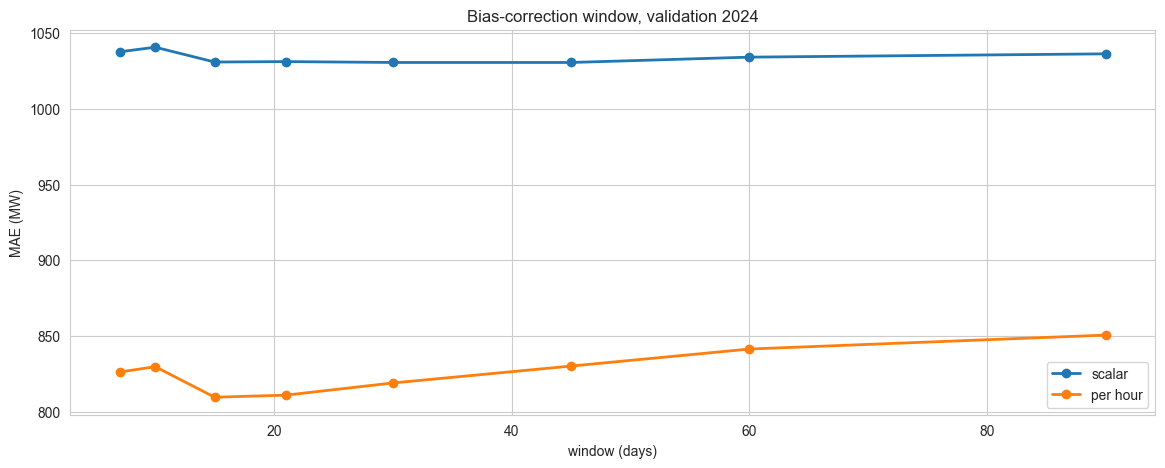

In [6]:
sweep.plot(marker='o', linewidth=2)
plt.title('Bias-correction window, validation 2024')
plt.xlabel('window (days)')
plt.ylabel('MAE (MW)')
plt.show()

Window length barely matters for the scalar correction and clearly matters per hour: eachhour gets only one observation per day, so the window trades noise against responsiveness.

## 4. The barThree rungs. Persistence says whether the problem is hard at all; RTE raw is what we alreadyget for free; RTE debiased is what we get for free *after five minutes of thought*.

In [7]:
preds = {k: v.loc[test.index] for k, v in naive.all_baselines(df, WINDOW).items()}
table = metrics.score_table(test['load_mw'], preds, reference='rte_raw')
print('TEST 2025-01 -> 2026-06')
print(table.round(1).to_string())

TEST 2025-01 -> 2026-06
                            MAE    RMSE  MAPE    bias  hours  gain_vs_rte_raw
persistence_7d           3674.7  5271.6   6.8  -153.5  13103           -153.9
rte_raw                  1447.6  1781.5   2.9  1055.2  13102              0.0
rte_debiased_scalar_15d  1120.4  1431.3   2.2   -10.2  13102             22.6
rte_debiased_hourly_15d   844.8  1110.5   1.7   -10.1  13102             41.6


In [8]:
peaks = pd.DataFrame({k: metrics.on_peaks(test['load_mw'], p) for k, p in preds.items()}).T
print('Winter evening peaks only (18-21h, DJF) - the expensive hours')
print(peaks.round(1).to_string())

Winter evening peaks only (18-21h, DJF) - the expensive hours
                            MAE    RMSE  MAPE    bias  hours
persistence_7d           5497.4  6790.2   8.3  -750.5  596.0
rte_raw                  1752.7  2125.2   2.6  1042.6  596.0
rte_debiased_scalar_15d  1553.2  1923.8   2.3   267.2  596.0
rte_debiased_hourly_15d  1173.8  1476.2   1.8   -74.5  596.0


## 5. Where the gain comes from

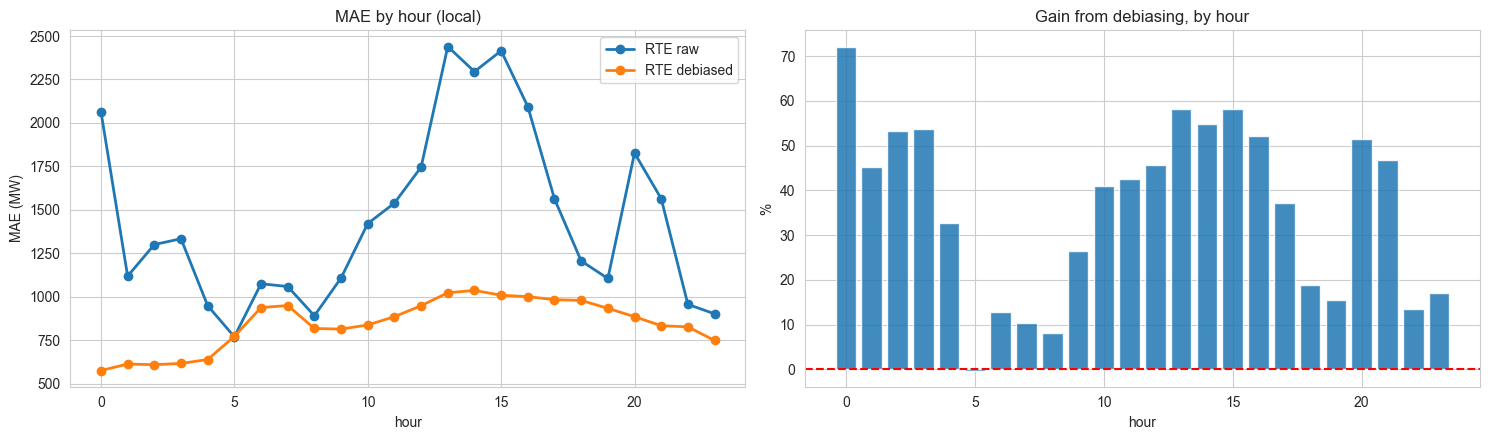

In [9]:
raw = metrics.by_hour(test['load_mw'], preds['rte_raw'])
fixed = metrics.by_hour(test['load_mw'], preds[f'rte_debiased_hourly_{WINDOW}d'])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(raw.index, raw.values, marker='o', label='RTE raw', linewidth=2)
axes[0].plot(fixed.index, fixed.values, marker='o', label='RTE debiased', linewidth=2)
axes[0].set_title('MAE by hour (local)')
axes[0].set_xlabel('hour')
axes[0].set_ylabel('MAE (MW)')
axes[0].legend()

gain = (raw - fixed) / raw * 100
axes[1].bar(gain.index, gain.values, alpha=0.85)
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_title('Gain from debiasing, by hour')
axes[1].set_xlabel('hour')
axes[1].set_ylabel('%')
plt.tight_layout()
plt.show()

The gain tracks the bias structure exactly: largest where RTE's bias was largest, andessentially zero at 5h where it was already unbiased. That coherence is the sanity check -the correction is removing a real, structured error, not fitting noise.Note also that debiasing **flattens** the error profile. Raw RTE ranges from 770 to 2440 MWacross hours; corrected, it sits between roughly 580 and 1040. Less of the error is nowpredictable from the clock alone, which is precisely what makes the remainder hard.

## 6. What this means for the modelling branches**The bar is RTE debiased, not RTE raw.** Comparing against raw RTE would hand us a ~42%gain before writing a single model. Every later result is reported against the correctedbaseline.**Lag 1h and lag 24h are unavailable.** The strongest autocorrelations in the EDA are offlimits. Usable load history starts at lag 48h, plus the load observed at the cutoff andaggregates of fully observed days.**Temperature results are an optimistic bound** until the weather-error sensitivity is run.**Beating 845 MW is genuinely hard**, and failing to do so is a legitimate finding: it wouldsay that a rolling recalibration of the public forecast is what should be deployed.